# Assignment Module 2: Aircraft Classification

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https:///raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)

## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
from tqdm import tqdm

import random
from collections import Counter

import matplotlib.pyplot as plt

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
from PIL import Image
import torchvision.transforms as transforms

class CropCopyrightAndResize:
    def __init__(self, size=(224, 336)):
        self.size = size  # (H, W)

    def __call__(self, img):
        w, h = img.size

        # 1. crop 20px bottom
        img = img.crop((0, 0, w, h - 20))

        # 2. resize while preserving aspect ratio (downsample)
        img = transforms.functional.resize(img, self.size)

        return img

train_transform = transforms.Compose([
    CropCopyrightAndResize((224, 336)),

    # 1. Horizontal flip (very important)
    transforms.RandomHorizontalFlip(p=0.5),

    # 2. Small geometric variation
    transforms.RandomRotation(5),

    # 3. Mild photometric variation (optional but useful)
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    # 4. Very mild regularization (cutout-style)
    transforms.RandomErasing(
        p=0.1,
        scale=(0.02, 0.04),
        ratio=(0.5, 2.0),
        value=0
    ),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    CropCopyrightAndResize((224, 336)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

100%|██████████| 2.75G/2.75G [02:34<00:00, 17.8MB/s]


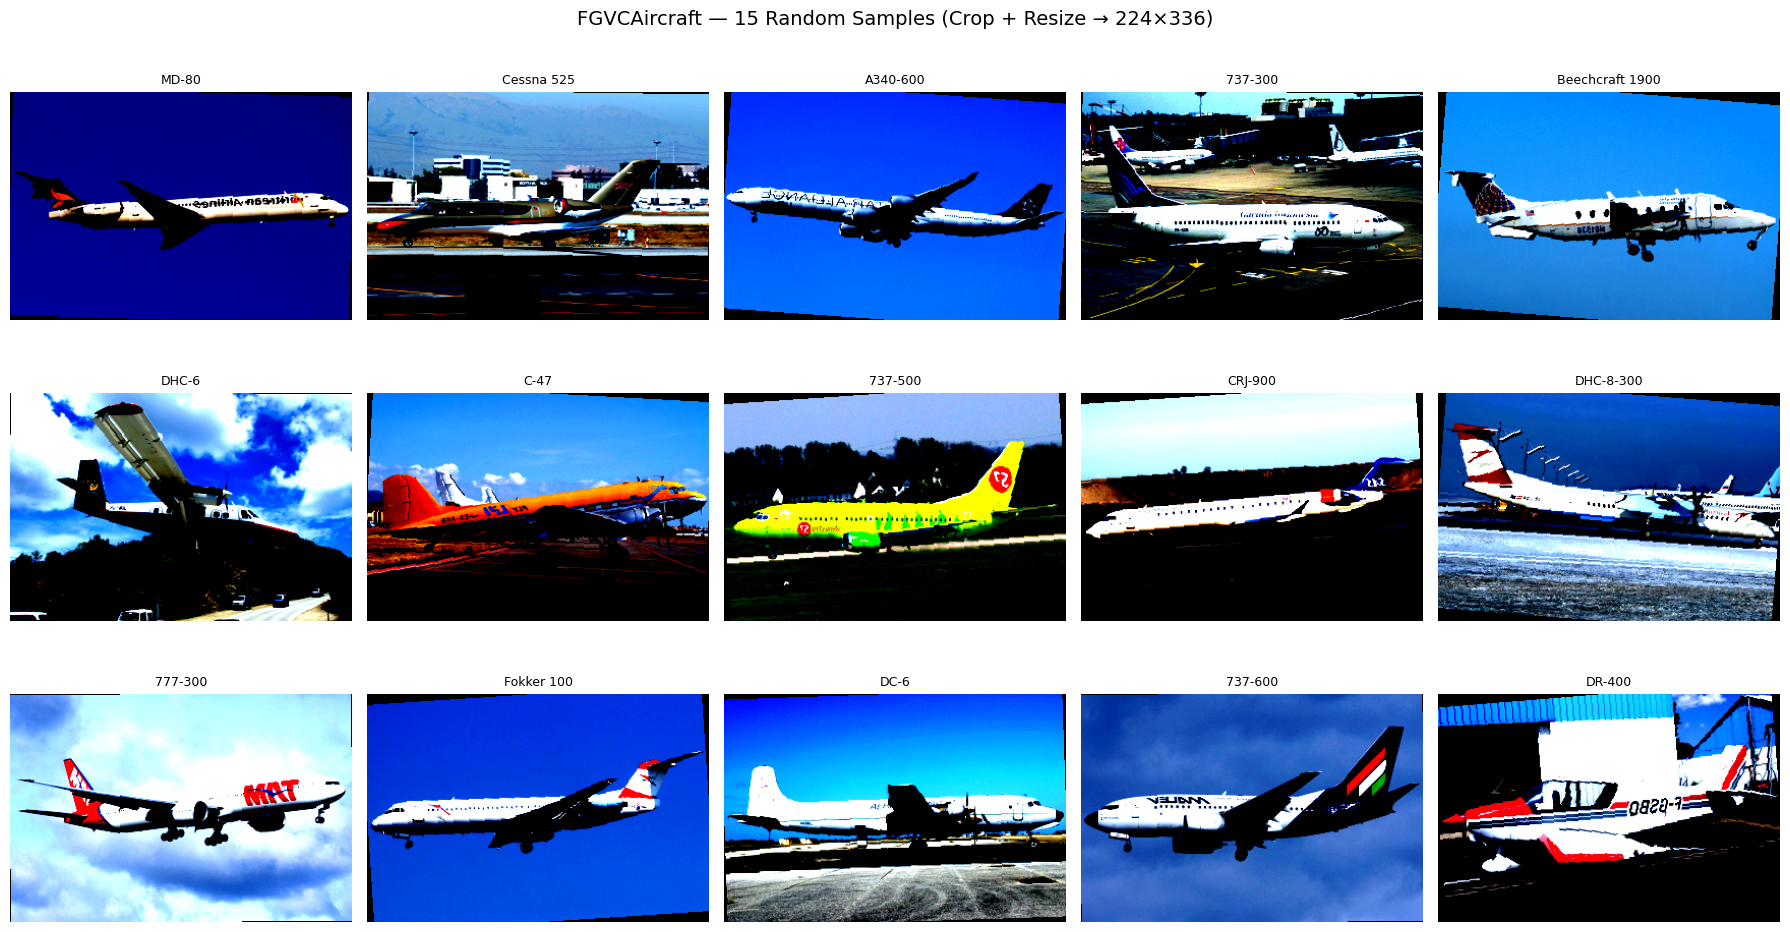

In [ ]:
# =========================================================
# Dataset (assumes already downloaded; no re-download cost)
# =========================================================
train_dataset = torchvision.datasets.FGVCAircraft(
    root="./data",
    split="trainval",
    annotation_level="variant",
    download=True,
    transform=train_transform
)

classes = train_dataset.classes

# =========================================================
# Visualize 15 random processed images
# =========================================================
num_images = 15
indices = random.sample(range(len(train_dataset)), num_images)

plt.figure(figsize=(18, 10))

for i, idx in enumerate(indices):

    image_tensor, label = train_dataset[idx]
    image = image_tensor.permute(1, 2, 0).numpy()

    plt.subplot(3, 5, i + 1)
    plt.imshow(image)
    plt.title(classes[label], fontsize=9)
    plt.axis("off")

plt.suptitle(
    "FGVCAircraft — 15 Random Samples (Crop + Resize → 224×336)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
test_dataset = torchvision.datasets.FGVCAircraft(
    root="./data",
    split="test",
    annotation_level="variant",
    download=True,
    transform=test_transform
)

In [ ]:
BATCH_SIZE = 32
NUM_CLASSES = 100
NUM_EPOCHS = 50
LEARNING_RATE = 3e-4

In [ ]:
# =========================================================
# DataLoaders
# =========================================================
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    persistent_workers=False,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    pin_memory=False
)

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

# Resources on fine-tuning and/or ResNet that we consulted as part of the research

| Name | URL | Resource type | Main takeaways |
|---|---|---|---|
| Transfer Learning for Computer Vision Tutorial | https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial | Documentation | This is just an introductory tutorial. Still, it's surprising that the fixed feature extractor approach performs slightly better than a full fine-tuning on the validation set - this is somewhat unexpected |
| Stanford CS231n: Transfer Learning | https://cs231n.github.io/transfer-learning/ | Class notes | The rules of thumb and practical advice presented are extremely useful. Since the dataset has 100 examples per image, 10k in total, and is focused on small variations of a single class of objects (significantly different from broad image recognition like ImageNet), this is a large, very different dataset situation. |
| Transfer Learning with ResNet in PyTorch | https://www.pluralsight.com/resources/blog/guides/introduction-to-resnet | Article | It's a very elementary  tutorial, with no particular insights. |
| Transfer Learning for PyTorch Image Classification | https://learnopencv.com/image-classification-using-transfer-learning-in-pytorch/ | Article | It's a very elementary  tutorial, with no particular insights.|
| Fine-Tuning a Pre-Trained ResNet-18 Model for Image Classification with PyTorch | https://edwinsamar.com/blog/2023/03/fine-tuning-pre-trained-resnet-18-model-image-classification-pytorch/ | Article | This is one of the main resources that uses ResNet-18 as the pre-trained model; it also demonstrates a two-stage training approach where the new classification head is trained for a small period with a higher learning rate, and full-network fine-tuning at a lower learning rate follows. |
| Transfer Learning with PyTorch: A Hands-On Guide | https://sigmoidal.ai/en/transfer-learning-with-pytorch/ | Article | Another resource that uses ResNet-18, instead demonstrating differential learning rates, where layers closer to the classification head learn faster in order to account for their more specialized learned features. |
| Practical Deep Learning for Coders — Lesson 1 | https://course.fast.ai/Lessons/lesson1.html | Various | It's a full course, the details of which we didn't explore - however, it did not seem to contain specifics that are directly relevant to our task. |
| PyTorch Pretrained Models Documentation | https://docs.pytorch.org/vision/stable/models.html | Documentation | Documentation that contains some information on the pre-trained ResNet-18 model we use. However, none of these details alter our work. |
| PyTorch Performance Tuning Guide | https://docs.pytorch.org/tutorials/recipes/recipes/tuning_guide.html | Documentation | This contains some performance-improving tricks, however, execution time is of secondary concern in the task at hand. |
| DeepWiki: Transfer Learning | https://deepwiki.com/pytorch/tutorials/3.1-transfer-learning | Article | A simple summary of some general aspects. |
| Fine-Tuning a Pre-Trained ResNet-18 Model for Image Classification on Custom Dataset with PyTorch | https://medium.com/@imabhi1216/fine-tuning-a-pre-trained-resnet-18-model-for-image-classification-on-custom-dataset-with-pytorch-02df12e83c2c | Article | Similar to other articles with code mentioned above. There aren't any unique takeaways from it. |
| Reddit Thread #1 | https://www.reddit.com/r/learnmachinelearning/comments/qa4z4p/making_transfer_learning_work_right_in_plain/ | Forum |An empty thread, there is nothing to take away from it. |
| Reddit Thread #2 | https://www.reddit.com/r/learnmachinelearning/comments/xd9ijr/transfer_learning_is_one_of_the_most_power/ | Forum |An empty thread, there is nothing to take away from it. |
| PyTorch Forum Thread: PyTorch Transfer Learning Methodology | https://discuss.pytorch.org/t/pytorch-transfer-learning-methodology/28370 | Forum | There is nothing directly useful besides resources already cited above. |
| PyTorch Forum Thread: Fine-Tuning ResNet Learning Rate | https://discuss.pytorch.org/t/fine-tuning-resnet-learning-rate/34327 | Forum | There is nothing directly useful. |
| Reddit Thread #3 | https://www.reddit.com/r/computervision/comments/1ls5xav/advice_and_tips_for_transfer_learning_and_fine/ | Forum | There is nothing directly useful. |
| YouTube Tutorial | https://www.youtube.com/watch?v=7nidEDz2Ysk | Video | There is nothing directly useful. |
| Deep Residual Learning for Image Recognition | https://arxiv.org/abs/1512.03385 | Paper | The original paper introducing ResNet. While it's a great expansion of the information presented in class, it's not directly applicable. |
| What Makes ImageNet Good for Transfer Learning? | https://arxiv.org/abs/1608.08614 | Paper | This was investigated out of interest; it is not directly relevant to the task, as the pre-training weights we use are fixed. |
| AutoAugment: Learning Augmentation Strategies from Data | https://arxiv.org/abs/1805.09501 | Paper | This is a very interesting approach, but overly complicated for what we do. It's also more closely intended for training from scratch than for fine-tuning. |
| Learning to Navigate for Fine-Grained Classification | https://arxiv.org/abs/1809.00287 | Paper (and code) | A really interesting paper, but the RL approach is too complicated for the task at hand. They provide some hyperparameters for the ResNet-50 they use, but that's a significantly different model from ResNet-18 given the bigger size and bottleneck blocks, so hyperparameters wouldn't be transferable. |
| ELoPE | https://arxiv.org/abs/1911.07344 | Paper | An interesting approach, but overly complicated for what we do. |
| Rethinking the Parameters for Fine-Tuning | https://arxiv.org/abs/2002.11770 | Paper | Explores the use of momentum for datasets substantially different from ImageNet (FGVC Aircrafts is one of them); there are some experimental parameter combinations given but the key takeaway is that a large momentum is what we should use IF all other hyperparams stay fixed. However, in general, there is the notion of effective learning rate, such that each hyperparameter affects the real learning speed. In general, a large source-target dataset disparity (as in FGVC Aircrafts) requires a larger ELR since we are looking to train a larger perturbation of the original weights. This only goes for fine-tuning and doesn't apply to training from scratch. Optimal weight decay is inversely related to optimal learning rate. |
| Revisiting ResNets: Improved Training and Scaling Strategies | https://arxiv.org/abs/2103.07579 | Paper | "Slow image resolution scaling" is an interesting concept, but not elaborated in much detail. |
| Bridge the Gap between Supervised and Unsupervised Learning for Fine-Grained Classification | https://arxiv.org/abs/2203.00441 | Paper | Interesting work, but they don't provide the full hyperparameters of the ResNet-50 backbone because it's not the main focus. So, ultimately not very relevant. |
| Top-Tuning: Efficient Alternative to Fine-Tuning | https://arxiv.org/abs/2209.07932 | Paper | An interesting approach, but fundamentally different to the task at hand. |
| Adaptive Multi-Source Domain Adaptation for Fine-Grained Classification | https://pmc.ncbi.nlm.nih.gov/articles/PMC11232598/ | Paper |  An interesting approach, but fundamentally different to the task at hand. |
| Effective and Efficient Optimization Methods for Deep Learning, Chapter 4 | https://theses.lib.polyu.edu.hk/bitstream/200/12027/3/6401.pdf | PhD Thesis | This is a very interesting approach, but overly complicated for what we do. |
| Syzarseef's FGVC-Aircraft Project | https://huggingface.co/Syzarseef/FGVC-Aircraft | Repository | A project that uses the exact ResNet-18 + FGVC-Aircraft dataset combination that the task requires - the main limitation is that the classification is done on 10 random classes instead of the full dataset, which fundamentally changes many aspects of the fine-tuning. |

# Summary of results from different fine-tuning regimes

| Model name         | Training stages | (Starting) Learning rate | Learning rate schedule           | Number of epochs | Other details                                                                                                                                  | Test accuracy | Test loss | Best epoch |
| ------------------ | --------------- | ------------------------ | -------------------------------- | ---------------: | ---------------------------------------------------------------------------------------------------------------------------------------------- | ------------: | --------: | ---------: |
| Model 1 (Baseline) | 1               | 3e-4                     | Static                           |               50 | None                                                                                                                                           |        0.8398 |    1.3613 |         42 |
| Model 2            | 2               | 1e-3, 1e-4               | Static                           |             5+25 | The new FC layer trains for 5 epochs at a 1e-3 LR, followed by 25 epochs of full fine-tuning at 3e-4.                                          |        0.8170 |    1.5256 |         29 |
| <u>**Model 3**</u> | <u>**2**</u> | <u>**1e-3, 1e-3**</u> | <u>**Warm-up -> cosine decay**</u> | <u>**5+35**</u> | <u>**Both training stages start with a 1e-5 warm-up, ramp up to 1e-3, then follow a cosine LR schedule until a minimum LR of 1e-5/1e-7.**</u> | <u>**0.8713**</u> | <u>**1.3140**</u> | <u>**37**</u> |
| Model 4            | 2               | 1e-3, 3e-4               | Warm-up -> cosine decay           |             5+35 | Model 4's training is almost the same as model 3's, but the fine-tuning has a maximum LR of 3e-4 and a warm-up LR of 3e-6                                   |        0.8644 |    1.3847 |         40 |
| Model 5            | 1               | 1e-3                     | Reduce LR on plateau (factor: 5) |               40 | The training reaches the minimum LR allowed by epoch 35.                                                                                       |        0.8425 |    1.3983 |         30 |
| Model 6            | 1               | 1e-3, 1e-6, 3e-7, 1e-7   | Cosine decay                     |               40 | The stem and first ResNet block are frozen; the other layers train with differential learning rates, starting from the LRs listed to the left. |        0.6475 |    2.0401 |         37 |
| Model 7            | 1               | 1e-3, 1e-4, 1e-5, 1e-6   | Cosine decay                     |               40 | Model 7's training is almost identical to model 6, except the non-FC non-frozen layers get substantially higher max learning rates.           |        0.7579 |    1.7964 |         38 |

# Elaboration on the experimental models

We start with a baseline fine-tuning, as per the requirement in 2A, which uses the hyper-parameters that were used in the first part of the assignment. With these settings, we observe a large train-test accuracy gap, considering that to reach a test accuracy of ~0.84, we need to push the training set accuracy to ~1.0, where the model perfectly memorizes the training set. At the same time, we observe **heavily diminishing returns** for accuracies on both sets after around epoch 10, and we obtain **both the best train and the best test accuracy in the same epoch**, 42. Since from that point onward, both the train and test accuracy fluctuate slightly but never exceed the running optimal values, this is **not a case of overfitting** (which it would be were the training accuracy to keep increasing). Rather, we suspect that the learning rate, once reaching the plateau, is too large to permit descending into the local minimum, rather exhibiting the effect of "bouncing back and forth" across a gradient valley, associated with **excessive learning rates.**

A further challenge in fine-tuning neural networks is that when we use a pre-trained backbone and a newly initialized classifier head, we are looking to converge to different degrees of perturbation of their initial states. Due to the pre-training, **the backbone is already a good generalist visual classifier, and thus we are looking to avoid to move away too drastically from some of the learned weights, particularly in early layers.** At the same time, the classifier head usually needs a more aggressive learning rate to converge to an optimum, since it is randomly initialized.

Thus, we experiment with several models using a **2-stage training approach** - starting first with training just the classifier head at a high learning rate for a small number of epochs, then fine-tuning the entire network at a smaller learning rate, which could allow us the best of both worlds.

In **Model 2**, the head is trained at first with a learning rate ~3.33x faster than in model 1, while the full fine-tuning proceeds at a rate 1/3rd of the baseline. Further, the number of epochs is reduced due  to the observed diminishing returns effect. However, this results in inferior results compared to the baseline, potentially because of poor weight initialization or, especially, **the static learning rate which doesn't work equally well for all stages of learning.**

Therefore, in **Models 3 and 4**, we introduce dynamic learning rate schedules for both phases, each having a **1-epoch warm-up to allow escaping from poor initalization regions, followed by a cosine decay schedule** with the intention to start with a high learning rate in both phases, in order to make **major early gains in the gradient descent, and then gently converge closer to the global optimum**. Model 3 uses 1e-3 as the starting learning rate for both training stages and **obtains the overall best result**, exceeding a test accuracy of 0.87. Since 3e-4 proved to be a decent-performing learning-rate for the full network on the baseline model, we change the maximum learning rate of stage 2 in Model 4 to 3e-4, **looking to check if we reach a "goldilocks zone"**. However, despite outperforming the baseline by a good margin, Model 3 remains the most accurate.

In Models 5-7, we revert to a 1-stage training regime in order to experiment with alternative approaches.

**Model 5** represents an experiment with **the "reduce LR on plateau" approach**: instead of using a predetermined schedule, here, we dynamically reduce the learning rate once a plateau - described above as "diminishing returns" - is reached. However, **this approach reduces the learning rate by a static factor** - in this case, by a factor of 5. Despite this inflexibility, Model 5 outperforms the baseline, but only just - and is far from matching Model 3. There may be variations of this strategy that work more effectively depending on the factor chosen, but **investigating them requires a lot of trial-and-error.**

Finally, **Models 6 and 7** represent a foray into **differential learning rate training strategies**: here, we specify diverse (starting) learning rates for any arbitrary choice of layers. In our case, we freeze the stem and first ResNet block of the model, since the features learned by them are highly general, and specify different learning rates for blocks 2,3, 4, and the classification head, which then follow a cosine decay schedule. Model 6 has a **bigger learning rate difference between the classifier head and the backbone** (block 4 and the classifier head's learning rates differ by a factor of 1000), while in Model 7, these differences are more gentle. In both cases, we observe **exceptionally poor results**, significantly worse than the baseline, especially so with Model 6.

A general theme noticed across the experiments is that **fine-tuning for FGVC-Aircraft doesn't benefit from introducing significant differences in learning rates between the classification head and the backbone.** This effect may be due to **large differences between the source (ImageNet) and target (FGVC-Aircraft) datasets**: the former has a larger number of highly visually distinct classes of objects, presented in various contexts, whereas differences between classes in the latter are highly fine-grained, since most aircrafts share a high degree of visual similarity, and many instances are photographed at similar scales, rotations, angles, with a similar background settings. Thus, **the weights perturbation required from the pre-trained backbone is likely larger** than some other fine-tuning use cases.

All but one of our models, including the baseline, exceed the stated threshold of ~70% accuracy on the test set. We hypothesize that this is the result of our **robust data augmentation approach,** carried over from the assignment's first part, allowing strong generalization capabilities to each model.

In [ ]:
import time
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.IMAGENET1K_V1

In [ ]:
# =========================================================
# Model
# =========================================================

model = resnet18(weights=weights)

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


In [ ]:
# =========================================================
# Loss + Optimizer
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)


# =========================================================
# Accuracy function
# =========================================================

def compute_accuracy(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            preds = logits.argmax(dim=1)

            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

In [ ]:
# =========================================================
# Evaluation function
#
# Returns BOTH loss and accuracy
# =========================================================

def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits = model(x)

            loss = criterion(logits, y)

            running_loss += loss.item() * y.size(0)

            preds = logits.argmax(dim=1)

            correct += (preds == y).sum().item()
            total += y.size(0)

    avg_loss = running_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


# =========================================================
# TRAINING HISTORY
# =========================================================

train_loss_list = []
test_loss_list = []

train_acc_list = []
test_acc_list = []

learning_rate_list = []

epoch_time_list = []


# =========================================================
# BEST MODEL TRACKING"
# =========================================================

best_test_acc = 0.0
best_epoch = -1

best_model_state = None

In [ ]:
# =========================================================
# IMPORTS
# =========================================================

import os
import time
import copy
import torch
from tqdm.auto import tqdm
from google.colab import drive


# =========================================================
# CONNECT GOOGLE DRIVE
# =========================================================

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    SAVE_DIR,
    "best_model.pth"
)

print("Checkpoint location:", CHECKPOINT_PATH)


# =========================================================
# INITIALIZE TRAINING INFORMATION
# =========================================================

start_epoch = 0
best_test_acc = 0.0
best_epoch = 0
best_model_state = None

train_loss_list = []
test_loss_list = []

train_acc_list = []
test_acc_list = []

learning_rate_list = []
epoch_time_list = []


# =========================================================
# OPTIONAL: RESUME FROM AN EXISTING CHECKPOINT
# =========================================================

RESUME_TRAINING = True

if RESUME_TRAINING and os.path.exists(CHECKPOINT_PATH):

    print("Loading existing checkpoint...")

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = checkpoint["epoch"]
    best_epoch = checkpoint.get(
        "best_epoch",
        start_epoch
    )

    best_test_acc = checkpoint.get(
        "best_test_acc",
        checkpoint.get("test_acc", 0.0)
    )

    train_loss_list = checkpoint.get(
        "train_loss_list",
        []
    )

    test_loss_list = checkpoint.get(
        "test_loss_list",
        []
    )

    train_acc_list = checkpoint.get(
        "train_acc_list",
        []
    )

    test_acc_list = checkpoint.get(
        "test_acc_list",
        []
    )

    learning_rate_list = checkpoint.get(
        "learning_rate_list",
        []
    )

    epoch_time_list = checkpoint.get(
        "epoch_time_list",
        []
    )

    best_model_state = copy.deepcopy(
        model.state_dict()
    )

    print(
        f"✅ Checkpoint loaded\n"
        f"Starting from epoch: {start_epoch + 1}\n"
        f"Best test accuracy: "
        f"{best_test_acc * 100:.2f}%"
    )

else:

    print("Starting training from the beginning.")


# =========================================================
# TRAINING LOOP
# =========================================================

for epoch in range(start_epoch, NUM_EPOCHS):

    epoch_start_time = time.time()

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for x, y in loop:

        # Move data to CPU/GPU
        x = x.to(device)
        y = y.to(device)

        # -------------------------------------------------
        # FORWARD PASS
        # -------------------------------------------------

        logits = model(x)
        loss = criterion(logits, y)

        # -------------------------------------------------
        # BACKWARD PASS
        # -------------------------------------------------

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # -------------------------------------------------
        # TRAINING STATISTICS
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        # -------------------------------------------------
        # PROGRESS BAR
        # -------------------------------------------------

        loop.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{correct / total:.4f}"
        )


    # =====================================================
    # TRAINING METRICS
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total


    # =====================================================
    # TEST METRICS
    # =====================================================

    test_loss, test_acc = evaluate(
        model,
        test_loader,
        criterion
    )


    # =====================================================
    # LEARNING RATE AND TIME
    # =====================================================

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start_time


    # =====================================================
    # STORE HISTORY
    # =====================================================

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    epoch_time_list.append(epoch_time)


    # =====================================================
    # PRINT EPOCH SUMMARY
    # =====================================================

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
        f"\n  Train Loss: {train_loss:.4f}"
        f"\n  Test Loss:  {test_loss:.4f}"
        f"\n  Train Acc:  {train_acc:.4f} "
        f"({train_acc * 100:.2f}%)"
        f"\n  Test Acc:   {test_acc:.4f} "
        f"({test_acc * 100:.2f}%)"
        f"\n  LR:         {current_lr:.2e}"
        f"\n  Time:       {epoch_time:.1f}s"
    )


    # =====================================================
    # SAVE BEST MODEL TO GOOGLE DRIVE
    # =====================================================

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "best_epoch": best_epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_test_acc":
                    best_test_acc,

                "test_acc":
                    test_acc,

                "test_loss":
                    test_loss,

                "train_acc":
                    train_acc,

                "train_loss":
                    train_loss,

                "train_loss_list":
                    train_loss_list,

                "test_loss_list":
                    test_loss_list,

                "train_acc_list":
                    train_acc_list,

                "test_acc_list":
                    test_acc_list,

                "learning_rate_list":
                    learning_rate_list,

                "epoch_time_list":
                    epoch_time_list,
            },
            CHECKPOINT_PATH
        )

        print(
            f"\n✅ New best model saved to Google Drive!"
            f"\nEpoch: {best_epoch}"
            f"\nAccuracy: {best_test_acc * 100:.2f}%"
            f"\nLocation: {CHECKPOINT_PATH}"
        )

    else:

        print(
            f"\nNo improvement. "
            f"Best accuracy remains "
            f"{best_test_acc * 100:.2f}%"
        )


# =========================================================
# RESTORE THE BEST MODEL
# =========================================================

if best_model_state is not None:

    model.load_state_dict(best_model_state)

    print(
        f"\n✅ Restored best model"
        f"\nBest epoch: {best_epoch}"
        f"\nBest test accuracy: "
        f"{best_test_acc * 100:.2f}%"
    )


# =========================================================
# FINAL MESSAGE
# =========================================================

print(
    f"\nTraining finished."
    f"\nBest model is stored at:"
    f"\n{CHECKPOINT_PATH}"
)

Mounted at /content/drive
Checkpoint location: /content/drive/MyDrive/model_checkpoints/best_model.pth
Loading existing checkpoint...
✅ Checkpoint loaded
Starting from epoch: 51
Best test accuracy: 84.31%

✅ Restored best model
Best epoch: 50
Best test accuracy: 84.31%

Training finished.
Best model is stored at:
/content/drive/MyDrive/model_checkpoints/best_model.pth


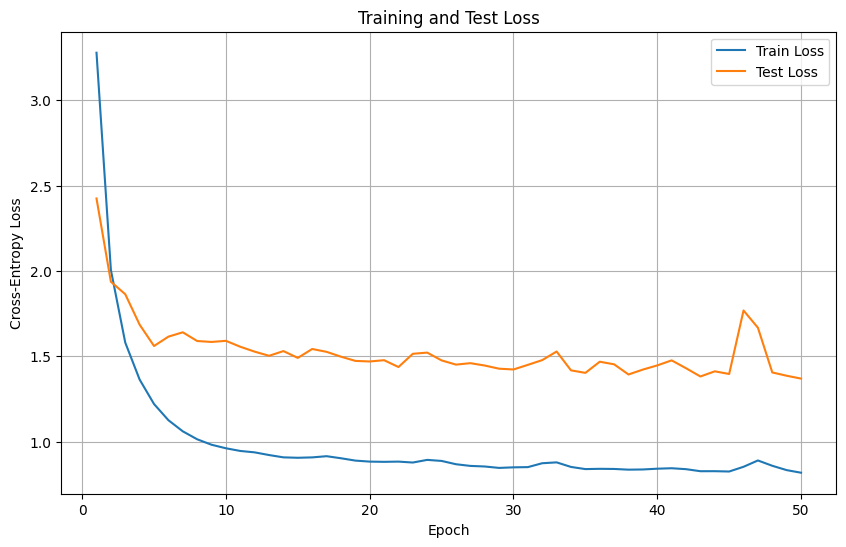

In [ ]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_loss_list,
    label="Train Loss"
)

plt.plot(
    epochs,
    test_loss_list,
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Test Loss")

plt.legend()
plt.grid(True)

plt.show()

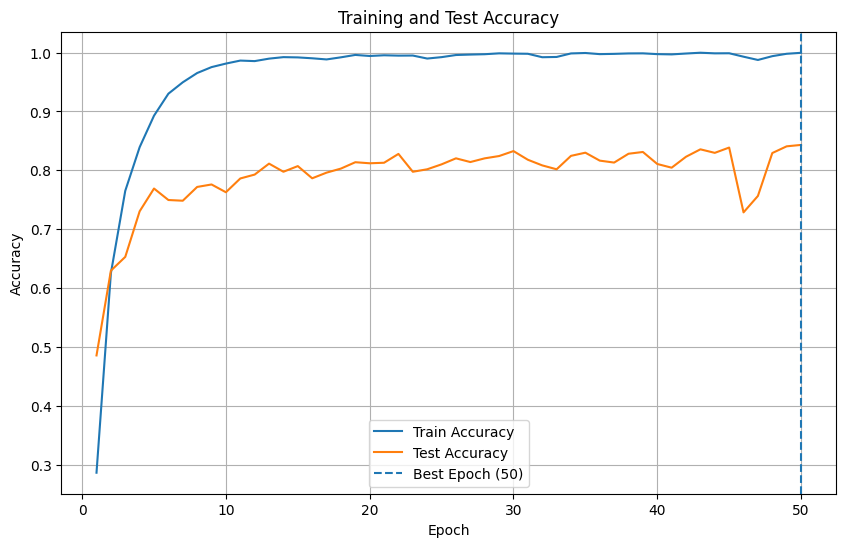

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_acc_list,
    label="Train Accuracy"
)

plt.plot(
    epochs,
    test_acc_list,
    label="Test Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Test Accuracy")

plt.legend()
plt.grid(True)

plt.show()

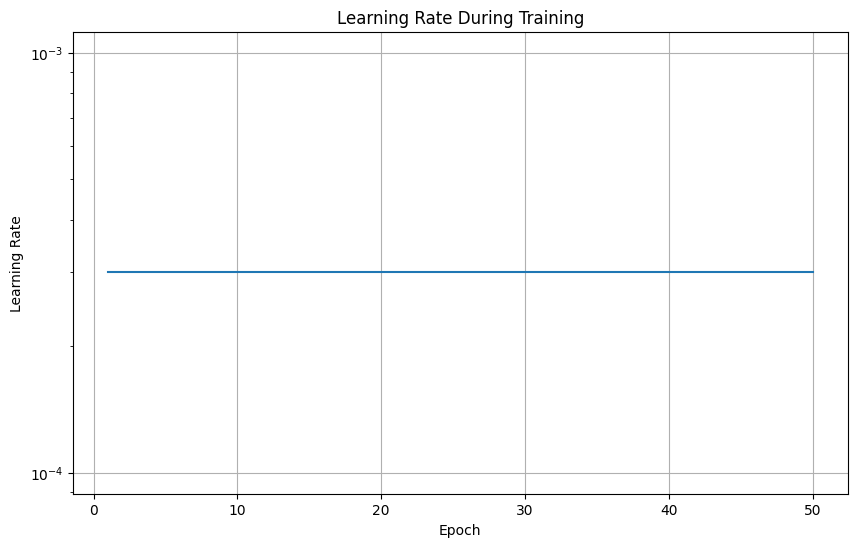

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    learning_rate_list
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate During Training")

plt.yscale("log")

plt.grid(True)

plt.show()

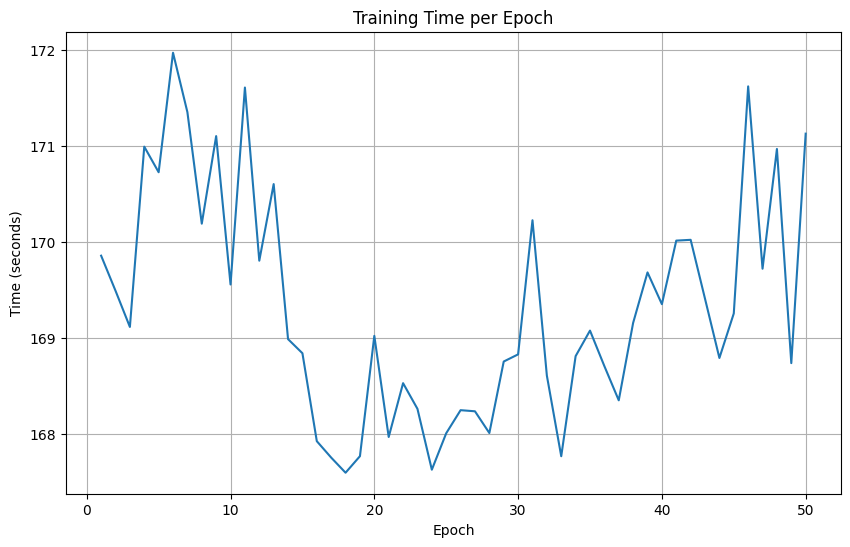

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    epoch_time_list
)

plt.xlabel("Epoch")
plt.ylabel("Time (seconds)")
plt.title("Training Time per Epoch")

plt.grid(True)

plt.show()

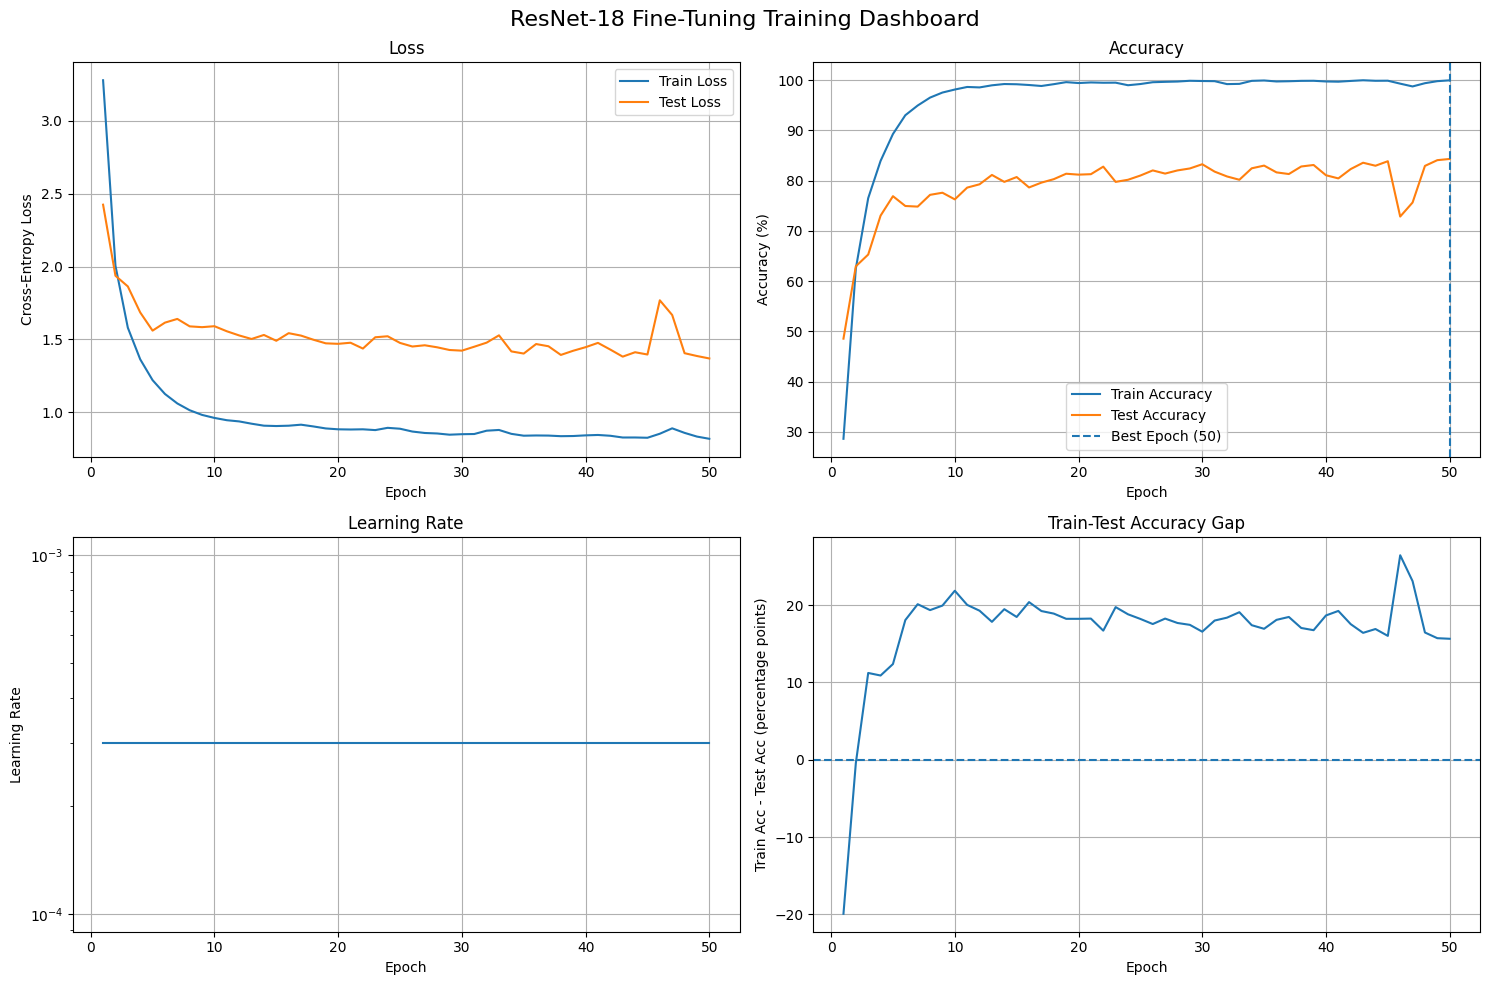

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10)
)

# =========================================================
# Loss
# =========================================================

axes[0, 0].plot(
    epochs,
    train_loss_list,
    label="Train Loss"
)

axes[0, 0].plot(
    epochs,
    test_loss_list,
    label="Test Loss"
)

axes[0, 0].set_title("Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Cross-Entropy Loss")

axes[0, 0].legend()
axes[0, 0].grid(True)


# =========================================================
# Accuracy
# =========================================================

axes[0, 1].plot(
    epochs,
    [x * 100 for x in train_acc_list],
    label="Train Accuracy"
)

axes[0, 1].plot(
    epochs,
    [x * 100 for x in test_acc_list],
    label="Test Accuracy"
)

axes[0, 1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy (%)")

axes[0, 1].legend()
axes[0, 1].grid(True)


# =========================================================
# Learning rate
# =========================================================

axes[1, 0].plot(
    epochs,
    learning_rate_list
)

axes[1, 0].set_title("Learning Rate")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Learning Rate")

axes[1, 0].set_yscale("log")

axes[1, 0].grid(True)


# =========================================================
# Generalization gap
# =========================================================

generalization_gap = [
    train_acc_list[i] - test_acc_list[i]
    for i in range(len(train_acc_list))
]

axes[1, 1].plot(
    epochs,
    [x * 100 for x in generalization_gap]
)

axes[1, 1].axhline(
    0,
    linestyle="--"
)

axes[1, 1].set_title(
    "Train-Test Accuracy Gap"
)

axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel(
    "Train Acc - Test Acc (percentage points)"
)

axes[1, 1].grid(True)


plt.suptitle(
    "ResNet-18 Fine-Tuning Training Dashboard",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [ ]:
for train, test, epoch in zip(train_acc_list, test_acc_list, range(1, NUM_EPOCHS + 1)):
    print(
        f"Epoch: {epoch} "
        f"Train accuracy: {train:.4f} "
        f"Test accuracy: {test:.4f}"
    )

Epoch: 1 Train accuracy: 0.2862 Test accuracy: 0.4854
Epoch: 2 Train accuracy: 0.6250 Test accuracy: 0.6295
Epoch: 3 Train accuracy: 0.7651 Test accuracy: 0.6529
Epoch: 4 Train accuracy: 0.8392 Test accuracy: 0.7303
Epoch: 5 Train accuracy: 0.8928 Test accuracy: 0.7690
Epoch: 6 Train accuracy: 0.9301 Test accuracy: 0.7495
Epoch: 7 Train accuracy: 0.9495 Test accuracy: 0.7483
Epoch: 8 Train accuracy: 0.9652 Test accuracy: 0.7717
Epoch: 9 Train accuracy: 0.9753 Test accuracy: 0.7759
Epoch: 10 Train accuracy: 0.9813 Test accuracy: 0.7627
Epoch: 11 Train accuracy: 0.9864 Test accuracy: 0.7861
Epoch: 12 Train accuracy: 0.9855 Test accuracy: 0.7927
Epoch: 13 Train accuracy: 0.9897 Test accuracy: 0.8113
Epoch: 14 Train accuracy: 0.9922 Test accuracy: 0.7975
Epoch: 15 Train accuracy: 0.9918 Test accuracy: 0.8071
Epoch: 16 Train accuracy: 0.9903 Test accuracy: 0.7864
Epoch: 17 Train accuracy: 0.9883 Test accuracy: 0.7960
Epoch: 18 Train accuracy: 0.9919 Test accuracy: 0.8029
Epoch: 19 Train acc

In [ ]:
# =========================================================
# Hyperparameters
# =========================================================

BATCH_SIZE = 32
NUM_CLASSES = 100

HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 25

HEAD_LR = 1e-3
FINETUNE_LR = 1e-4

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

In [ ]:
# =========================================================
# Model
# =========================================================

model_2 = resnet18(weights=weights)

# Replace ImageNet classifier with 100-class classifier
model_2.fc = nn.Linear(
    model_2.fc.in_features,
    NUM_CLASSES
)

model_2 = model_2.to(device)

# =========================================================
# Freeze backbone
# =========================================================

for param in model_2.parameters():
    param.requires_grad = False

# Unfreeze ONLY the classifier
for param in model_2.fc.parameters():
    param.requires_grad = True

In [ ]:
# =========================================================
# Loss
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

In [ ]:
# =========================================================
# Stage 1 optimizer
# =========================================================

optimizer = torch.optim.AdamW(
    model_2.fc.parameters(),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY
)

In [ ]:
# =========================================================
# Evaluation function
# =========================================================

def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits = model(x)

            loss = criterion(logits, y)

            running_loss += loss.item() * y.size(0)

            preds = logits.argmax(dim=1)

            correct += (preds == y).sum().item()
            total += y.size(0)

    avg_loss = running_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


# =========================================================
# Training history
# =========================================================

train_loss_list = []
test_loss_list = []

train_acc_list = []
test_acc_list = []

learning_rate_list = []

stage_list = []


# =========================================================
# Best model
# =========================================================

best_test_acc = 0.0
best_epoch = -1
best_model_state = None


In [ ]:

# =========================================================
# STAGE 1
# Train classifier head only
# =========================================================

print("=" * 70)
print("STAGE 1: CLASSIFIER HEAD ONLY")
print("=" * 70)

for epoch in range(HEAD_EPOCHS):

    epoch_start = time.time()

    model_2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Stage 1 | Epoch {epoch + 1}/{HEAD_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # Forward
        logits = model_2(x)

        loss = criterion(logits, y)

        # Backward
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # Statistics
        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # -----------------------------------------------------
    # Epoch metrics
    # -----------------------------------------------------

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_2,
        test_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Head")


    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_2.state_dict()
        )

        torch.save({
            "stage": 1,
            "epoch": epoch + 1,
            "model_state_dict": model_2.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )


STAGE 1: CLASSIFIER HEAD ONLY


Stage 1 | Epoch 1/5:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 4.4355 | Test Loss: 4.0835 | Train Acc: 0.0622 | Test Acc: 0.0975 | LR: 1.00e-03 | Time: 1872.2s
  ✓ New best model: 0.0975


Stage 1 | Epoch 2/5:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 3.8092 | Test Loss: 3.6738 | Train Acc: 0.1762 | Test Acc: 0.1932 | LR: 1.00e-03 | Time: 1925.9s
  ✓ New best model: 0.1932


...

Epoch 03 | Train Loss: 3.4658 | Test Loss: 3.4632 | Train Acc: 0.2652 | Test Acc: 0.2379 | LR: 1.00e-03 | Time: 1903.5s
  ✓ New best model: 0.2379


Stage 1 | Epoch 4/5:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 04 | Train Loss: 3.2290 | Test Loss: 3.3374 | Train Acc: 0.3249 | Test Acc: 0.2715 | LR: 1.00e-03 | Time: 1927.4s
  ✓ New best model: 0.2715


Stage 1 | Epoch 5/5:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 05 | Train Loss: 3.0808 | Test Loss: 3.1961 | Train Acc: 0.3561 | Test Acc: 0.2949 | LR: 1.00e-03 | Time: 1918.3s
  ✓ New best model: 0.2949


In [ ]:
# =========================================================
# STAGE 2
# Unfreeze entire ResNet
# =========================================================

print("\n" + "=" * 70)
print("STAGE 2: FULL NETWORK FINE-TUNING")
print("=" * 70)


# ---------------------------------------------------------
# Unfreeze entire model
# ---------------------------------------------------------

for param in model_2.parameters():
    param.requires_grad = True


# ---------------------------------------------------------
# IMPORTANT:
# Create a NEW optimizer for Stage 2
# ---------------------------------------------------------

optimizer = torch.optim.AdamW(
    model_2.parameters(),
    lr=FINETUNE_LR,
    weight_decay=WEIGHT_DECAY
)


# =========================================================
# Stage 2 training
# =========================================================

for epoch in range(FINETUNE_EPOCHS):

    epoch_start = time.time()

    model_2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    global_epoch = HEAD_EPOCHS + epoch + 1

    loop = tqdm(
        train_loader,
        desc=(
            f"Stage 2 | "
            f"Epoch {epoch + 1}/{FINETUNE_EPOCHS}"
        )
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # Forward
        logits = model_2(x)

        loss = criterion(logits, y)

        # Backward
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # Statistics
        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # -----------------------------------------------------
    # Epoch metrics
    # -----------------------------------------------------

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_2,
        test_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Full")


    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {global_epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )


    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = global_epoch

        best_model_state = copy.deepcopy(
            model_2.state_dict()
        )

        torch.save({
            "stage": 2,
            "epoch": global_epoch,
            "model_state_dict": model_2.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )


In [ ]:
# =========================================================
# Restore best model
# =========================================================

model_2.load_state_dict(best_model_state)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best test accuracy: "
    f"{best_test_acc:.4f} "
    f"({best_test_acc * 100:.2f}%)"
)

In [ ]:
epochs = range(1, len(train_acc_list) + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    epochs,
    [x * 100 for x in train_acc_list],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in test_acc_list],
    label="Test Accuracy"
)

plt.axvline(
    HEAD_EPOCHS,
    linestyle="--",
    label="Backbone Unfrozen"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Two-Stage Fine-Tuning: Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model_3 = resnet18(weights=weights)

# Replace ImageNet classifier with 100-class classifier
model_3.fc = nn.Linear(
    model_3.fc.in_features,
    NUM_CLASSES
)

model_3 = model_3.to(device)

# =========================================================
# Freeze backbone
# =========================================================

for param in model_3.parameters():
    param.requires_grad = False

# Unfreeze ONLY the classifier
for param in model_3.fc.parameters():
    param.requires_grad = True

In [ ]:
HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 35

In [ ]:
# =========================================================
# Stage 1 optimizer
# =========================================================

optimizer = torch.optim.AdamW(
    model_3.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# =========================================================
# Stage 1 scheduler
# =========================================================

warmup_epochs = 1
total_epochs = 5

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.01,     # 1e-5 / 1e-3
    end_factor=1.0,        # 1e-3
    total_iters=warmup_epochs
)

cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=total_epochs - warmup_epochs,
    eta_min=1e-5
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler
    ],
    milestones=[warmup_epochs]
)

In [ ]:
# =========================================================
# STAGE 1
# Train classifier head only
# =========================================================

print("=" * 70)
print("STAGE 1: CLASSIFIER HEAD ONLY")
print("=" * 70)

for epoch in range(HEAD_EPOCHS):

    epoch_start = time.time()

    model_3.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Stage 1 | Epoch {epoch + 1}/{HEAD_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # Forward
        logits = model_3(x)

        loss = criterion(logits, y)

        # Backward
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # Statistics
        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # -----------------------------------------------------
    # Epoch metrics
    # -----------------------------------------------------

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_3,
        test_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Head")


    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_3.state_dict()
        )

        torch.save({
            "stage": 1,
            "epoch": epoch + 1,
            "model_state_dict": model_3.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    scheduler.step()


In [ ]:
# =========================================================
# Stage 2 optimizer
# =========================================================

# Unfreeze entire network
for param in model_3.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    model_3.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# =========================================================
# Stage 2 LR schedule
#
# Epoch 1: warmup 1e-5 -> 1e-3
# Epochs 2-35: cosine decay 1e-3 -> 1e-7
# =========================================================

warmup_epochs = 1
total_epochs = 35

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1e-2,     # 1e-5
    end_factor=1.0,        # 1e-3
    total_iters=warmup_epochs
)

cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=total_epochs - warmup_epochs,  # 34
    eta_min=1e-7
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler
    ],
    milestones=[warmup_epochs]
)

In [ ]:
# =========================================================
# STAGE 2
# Unfreeze entire ResNet
# =========================================================

print("\n" + "=" * 70)
print("STAGE 2: FULL NETWORK FINE-TUNING")
print("=" * 70)

# ---------------------------------------------------------
# Unfreeze entire model
# ---------------------------------------------------------

for param in model_3.parameters():
    param.requires_grad = True


# =========================================================
# Stage 2 training
# =========================================================

for epoch in range(FINETUNE_EPOCHS):

    epoch_start = time.time()

    model_3.train()

    running_loss = 0.0
    correct = 0
    total = 0

    global_epoch = HEAD_EPOCHS + epoch + 1

    loop = tqdm(
        train_loader,
        desc=(
            f"Stage 2 | "
            f"Epoch {epoch + 1}/{FINETUNE_EPOCHS}"
        )
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # -------------------------------------------------
        # Forward
        # -------------------------------------------------

        logits = model_3(x)

        loss = criterion(logits, y)

        # -------------------------------------------------
        # Backward
        # -------------------------------------------------

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------------------------------
        # Statistics
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # Epoch metrics
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_3,
        test_loader,
        criterion
    )

    # LR used during THIS epoch
    current_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------------------------------
    # Store metrics
    # -----------------------------------------------------

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Full")

    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {global_epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = global_epoch

        best_model_state = copy.deepcopy(
            model_3.state_dict()
        )

        torch.save({
            "stage": 2,
            "epoch": global_epoch,
            "model_state_dict": model_3.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    # =====================================================
    # Advance LR scheduler
    # =====================================================

    scheduler.step()

In [ ]:
# =========================================================
# Restore best model
# =========================================================

model_3.load_state_dict(best_model_state)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best test accuracy: "
    f"{best_test_acc:.4f} "
    f"({best_test_acc * 100:.2f}%)"
)

In [ ]:
epochs = range(1, len(train_acc_list) + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    epochs,
    [x * 100 for x in train_acc_list],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in test_acc_list],
    label="Test Accuracy"
)

plt.axvline(
    HEAD_EPOCHS,
    linestyle="--",
    label="Backbone Unfrozen"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Two-Stage Fine-Tuning (LR schedules): Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
weights = ResNet18_Weights.IMAGENET1K_V1
model_4 = resnet18(weights=weights)

# Replace ImageNet classifier with 100-class classifier
model_4.fc = nn.Linear(
    model_4.fc.in_features,
    NUM_CLASSES
)

model_4 = model_4.to(device)

# =========================================================
# Freeze backbone
# =========================================================

for param in model_4.parameters():
    param.requires_grad = False

# Unfreeze ONLY the classifier
for param in model_4.fc.parameters():
    param.requires_grad = True

In [ ]:
# =========================================================
# Stage 1 optimizer
# =========================================================

optimizer = torch.optim.AdamW(
    model_4.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# =========================================================
# Stage 1 scheduler
# =========================================================

warmup_epochs = 1
total_epochs = 5

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.01,     # 1e-5 / 1e-3
    end_factor=1.0,        # 1e-3
    total_iters=warmup_epochs
)

cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=total_epochs - warmup_epochs,
    eta_min=1e-5
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler
    ],
    milestones=[warmup_epochs]
)

In [ ]:
# =========================================================
# STAGE 1
# Train classifier head only
# =========================================================

print("=" * 70)
print("STAGE 1: CLASSIFIER HEAD ONLY")
print("=" * 70)

for epoch in range(HEAD_EPOCHS):

    epoch_start = time.time()

    model_4.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Stage 1 | Epoch {epoch + 1}/{HEAD_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # Forward
        logits = model_4(x)

        loss = criterion(logits, y)

        # Backward
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # Statistics
        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # -----------------------------------------------------
    # Epoch metrics
    # -----------------------------------------------------

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_4,
        test_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Head")


    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_4.state_dict()
        )

        torch.save({
            "stage": 1,
            "epoch": epoch + 1,
            "model_state_dict": model_4.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    scheduler.step()


In [ ]:
# =========================================================
# Stage 2 optimizer
# =========================================================

# Unfreeze entire network
for param in model_4.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    model_4.parameters(),
    lr=3e-4,              # maximum LR after warmup
    weight_decay=1e-4
)

# =========================================================
# Stage 2 LR schedule
#
# Epoch 1: warmup 3e-6 -> 3e-4
# Epochs 2-35: cosine decay 3e-4 -> 1e-7
# =========================================================

warmup_epochs = 1
total_epochs = 35

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1e-2,     # 3e-4 * 0.01 = 3e-6
    end_factor=1.0,       # 3e-4
    total_iters=warmup_epochs
)

cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=total_epochs - warmup_epochs,  # 34 epochs
    eta_min=1e-7
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler
    ],
    milestones=[warmup_epochs]
)

In [ ]:
# =========================================================
# STAGE 2
# Unfreeze entire ResNet
# =========================================================

print("\n" + "=" * 70)
print("STAGE 2: FULL NETWORK FINE-TUNING")
print("=" * 70)

# ---------------------------------------------------------
# Unfreeze entire model
# ---------------------------------------------------------

for param in model_4.parameters():
    param.requires_grad = True


# =========================================================
# Stage 2 training
# =========================================================

for epoch in range(FINETUNE_EPOCHS):

    epoch_start = time.time()

    model_4.train()

    running_loss = 0.0
    correct = 0
    total = 0

    global_epoch = HEAD_EPOCHS + epoch + 1

    loop = tqdm(
        train_loader,
        desc=(
            f"Stage 2 | "
            f"Epoch {epoch + 1}/{FINETUNE_EPOCHS}"
        )
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # -------------------------------------------------
        # Forward
        # -------------------------------------------------

        logits = model_4(x)

        loss = criterion(logits, y)

        # -------------------------------------------------
        # Backward
        # -------------------------------------------------

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------------------------------
        # Statistics
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # Epoch metrics
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_4,
        test_loader,
        criterion
    )

    # LR used during THIS epoch
    current_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------------------------------
    # Store metrics
    # -----------------------------------------------------

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)
    stage_list.append("Full")

    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {global_epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # -----------------------------------------------------
    # Best checkpoint
    # -----------------------------------------------------

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = global_epoch

        best_model_state = copy.deepcopy(
            model_4.state_dict()
        )

        torch.save({
            "stage": 2,
            "epoch": global_epoch,
            "model_state_dict": model_4.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_two_stage_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    # =====================================================
    # Advance LR scheduler
    # =====================================================

    scheduler.step()

In [ ]:
# =========================================================
# MODEL
# =========================================================

model_5 = resnet18(weights=weights)

model_5.fc = nn.Linear(
    model_5.fc.in_features,
    NUM_CLASSES
)

model_5 = model_5.to(device)

# =========================================================
# Loss
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# =========================================================
# Optimizer
# =========================================================

optimizer = torch.optim.AdamW(
    model_5.parameters(),       # ALL parameters
    lr=1e-3,
    weight_decay=1e-4
)

# =========================================================
# LR scheduler
#
# Initial LR: 1e-3
# Reduce by factor of 5 after 2 epochs of no improvement
# Minimum LR: 1e-7
# =========================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.2,                 # 1e-3 -> 2e-4 -> 4e-5 -> ...
    patience=1,
    min_lr=1e-7
)

NUM_EPOCHS = 40

In [ ]:
# =========================================================
# SINGLE-STAGE FULL FINE-TUNING
# =========================================================

print("\n" + "=" * 70)
print("FULL RESNET-18 FINE-TUNING")
print("=" * 70)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model_5.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # -------------------------------------------------
        # Forward
        # -------------------------------------------------

        logits = model_5(x)

        loss = criterion(logits, y)

        # -------------------------------------------------
        # Backward
        # -------------------------------------------------

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------------------------------
        # Statistics
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # Epoch metrics
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_5,
        test_loader,
        criterion
    )

    # LR BEFORE scheduler.step()
    current_lr = optimizer.param_groups[0]["lr"]

    # -----------------------------------------------------
    # Store metrics
    # -----------------------------------------------------

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    learning_rate_list.append(current_lr)

    # -----------------------------------------------------
    # Output
    # -----------------------------------------------------

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # =====================================================
    # Best checkpoint
    # =====================================================

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_5.state_dict()
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model_5.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "test_acc": test_acc,
            "test_loss": test_loss,
            "train_acc": train_acc,
            "train_loss": train_loss
        }, "best_full_finetune_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    # =====================================================
    # LR scheduler
    # =====================================================

    scheduler.step(test_acc)

In [ ]:
import math
# =========================================================
# Model
# =========================================================

weights = ResNet18_Weights.IMAGENET1K_V1

model_6 = resnet18(weights=weights)

model_6.fc = nn.Linear(
    model_6.fc.in_features,
    NUM_CLASSES
)

model_6 = model_6.to(device)


# =========================================================
# Freeze early/general features
#
# Freeze:
#   - stem: conv1 + bn1
#   - layer1: first ResNet residual block group
#
# Train:
#   - layer2
#   - layer3
#   - layer4
#   - fc
# =========================================================

for param in model_6.conv1.parameters():
    param.requires_grad = False

for param in model_6.bn1.parameters():
    param.requires_grad = False

for param in model_6.layer1.parameters():
    param.requires_grad = False


# =========================================================
# Loss
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# =========================================================
# Differential learning rates
# =========================================================

optimizer = torch.optim.AdamW(
    [
        {
            "params": model_6.layer2.parameters(),
            "lr": 1e-7
        },
        {
            "params": model_6.layer3.parameters(),
            "lr": 1e-6
        },
        {
            "params": model_6.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model_6.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)


# =========================================================
# Cosine LR scheduler
#
# The SAME cosine multiplier is applied to every group,
# preserving the differential LR ratios.
#
# 1e-7  -> 1e-9
# 3e-7  -> 3e-9
# 1e-6  -> 1e-8
# 1e-3  -> 1e-5
# =========================================================

NUM_EPOCHS = 40

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch:
        0.01 + 0.99 * (
            0.5 * (
                1 + math.cos(
                    math.pi * epoch / (NUM_EPOCHS - 1)
                )
            )
        )
)

In [ ]:
# =========================================================
# DIFFERENTIAL LEARNING RATE FINE-TUNING
# =========================================================

print("\n" + "=" * 70)
print("DIFFERENTIAL LEARNING RATE FINE-TUNING")
print("=" * 70)


# =========================================================
# LR history
# =========================================================

layer2_lr_list = []
layer3_lr_list = []
layer4_lr_list = []
fc_lr_list = []


# =========================================================
# Print trainable / frozen layers
# =========================================================

print("\nTrainable layers:")

for name, param in model_6.named_parameters():

    if param.requires_grad:
        print(f"  {name}")

print("\nFrozen layers:")
print("  conv1")
print("  bn1")
print("  layer1")


# =========================================================
# Training
# =========================================================

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model_6.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # -------------------------------------------------
        # Forward
        # -------------------------------------------------

        logits = model_6(x)

        loss = criterion(logits, y)

        # -------------------------------------------------
        # Backward
        # -------------------------------------------------

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------------------------------
        # Statistics
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # Epoch metrics
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_6,
        test_loader,
        criterion
    )

    # =====================================================
    # Current learning rates
    # =====================================================

    layer2_lr = optimizer.param_groups[0]["lr"]
    layer3_lr = optimizer.param_groups[1]["lr"]
    layer4_lr = optimizer.param_groups[2]["lr"]
    fc_lr = optimizer.param_groups[3]["lr"]

    # =====================================================
    # Store metrics
    # =====================================================

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    # Store EACH learning rate separately
    layer2_lr_list.append(layer2_lr)
    layer3_lr_list.append(layer3_lr)
    layer4_lr_list.append(layer4_lr)
    fc_lr_list.append(fc_lr)

    # =====================================================
    # Output
    # =====================================================

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR layer2: {layer2_lr:.2e} | "
        f"LR layer3: {layer3_lr:.2e} | "
        f"LR layer4: {layer4_lr:.2e} | "
        f"LR fc: {fc_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # =====================================================
    # Best checkpoint
    # =====================================================

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_6.state_dict()
        )

        torch.save({
            "epoch": epoch + 1,

            "model_state_dict":
                model_6.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "test_acc":
                test_acc,

            "test_loss":
                test_loss,

            "train_acc":
                train_acc,

            "train_loss":
                train_loss,

            # Save the individual LRs too
            "layer2_lr":
                layer2_lr,

            "layer3_lr":
                layer3_lr,

            "layer4_lr":
                layer4_lr,

            "fc_lr":
                fc_lr

        }, "best_differential_lr_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    # =====================================================
    # Scheduler
    # =====================================================

    scheduler.step()

In [ ]:
# =========================================================
# Model
# =========================================================

weights = ResNet18_Weights.IMAGENET1K_V1

model_7 = resnet18(weights=weights)

model_7.fc = nn.Linear(
    model_7.fc.in_features,
    NUM_CLASSES
)

model_7 = model_7.to(device)


# =========================================================
# Freeze early/general features
#
# Freeze:
#   - stem: conv1 + bn1
#   - layer1: first ResNet residual block group
#
# Train:
#   - layer2
#   - layer3
#   - layer4
#   - fc
# =========================================================

for param in model_7.conv1.parameters():
    param.requires_grad = False

for param in model_7.bn1.parameters():
    param.requires_grad = False

for param in model_7.layer1.parameters():
    param.requires_grad = False


# =========================================================
# Loss
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# =========================================================
# Differential learning rates
# =========================================================

optimizer = torch.optim.AdamW(
    [
        {
            "params": model_7.layer2.parameters(),
            "lr": 1e-6
        },
        {
            "params": model_7.layer3.parameters(),
            "lr": 1e-5
        },
        {
            "params": model_7.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_7.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)


# =========================================================
# Cosine LR scheduler
#
# The SAME cosine multiplier is applied to every group,
# preserving the differential LR ratios.
#
# 1e-7  -> 1e-9
# 3e-7  -> 3e-9
# 1e-6  -> 1e-8
# 1e-3  -> 1e-5
# =========================================================

NUM_EPOCHS = 40

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch:
        0.01 + 0.99 * (
            0.5 * (
                1 + math.cos(
                    math.pi * epoch / (NUM_EPOCHS - 1)
                )
            )
        )
)

In [ ]:
# =========================================================
# DIFFERENTIAL LEARNING RATE FINE-TUNING
# =========================================================

print("\n" + "=" * 70)
print("DIFFERENTIAL LEARNING RATE FINE-TUNING")
print("=" * 70)


# =========================================================
# LR history
# =========================================================

layer2_lr_list = []
layer3_lr_list = []
layer4_lr_list = []
fc_lr_list = []


# =========================================================
# Print trainable / frozen layers
# =========================================================

print("\nTrainable layers:")

for name, param in model_7.named_parameters():

    if param.requires_grad:
        print(f"  {name}")

print("\nFrozen layers:")
print("  conv1")
print("  bn1")
print("  layer1")


# =========================================================
# Training
# =========================================================

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model_7.train()

    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for x, y in loop:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # -------------------------------------------------
        # Forward
        # -------------------------------------------------

        logits = model_7(x)

        loss = criterion(logits, y)

        # -------------------------------------------------
        # Backward
        # -------------------------------------------------

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------------------------------
        # Statistics
        # -------------------------------------------------

        batch_size = y.size(0)

        running_loss += loss.item() * batch_size

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += batch_size

        loop.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # =====================================================
    # Epoch metrics
    # =====================================================

    train_loss = running_loss / total
    train_acc = correct / total

    test_loss, test_acc = evaluate(
        model_7,
        test_loader,
        criterion
    )

    # =====================================================
    # Current learning rates
    # =====================================================

    layer2_lr = optimizer.param_groups[0]["lr"]
    layer3_lr = optimizer.param_groups[1]["lr"]
    layer4_lr = optimizer.param_groups[2]["lr"]
    fc_lr = optimizer.param_groups[3]["lr"]

    # =====================================================
    # Store metrics
    # =====================================================

    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)

    # Store EACH learning rate separately
    layer2_lr_list.append(layer2_lr)
    layer3_lr_list.append(layer3_lr)
    layer4_lr_list.append(layer4_lr)
    fc_lr_list.append(fc_lr)

    # =====================================================
    # Output
    # =====================================================

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f} | "
        f"LR layer2: {layer2_lr:.2e} | "
        f"LR layer3: {layer3_lr:.2e} | "
        f"LR layer4: {layer4_lr:.2e} | "
        f"LR fc: {fc_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    # =====================================================
    # Best checkpoint
    # =====================================================

    if test_acc > best_test_acc:

        best_test_acc = test_acc
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model_7.state_dict()
        )

        torch.save({
            "epoch": epoch + 1,

            "model_state_dict":
                model_7.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "test_acc":
                test_acc,

            "test_loss":
                test_loss,

            "train_acc":
                train_acc,

            "train_loss":
                train_loss,

            # Save the individual LRs too
            "layer2_lr":
                layer2_lr,

            "layer3_lr":
                layer3_lr,

            "layer4_lr":
                layer4_lr,

            "fc_lr":
                fc_lr

        }, "best_differential_lr_model.pth")

        print(
            f"  ✓ New best model: "
            f"{test_acc:.4f}"
        )

    # =====================================================
    # Scheduler
    # =====================================================

    scheduler.step()

## Augmentation ablation study

To measure the effect of data augmentation, all experiments below use the same ResNet-18 initialization, optimizer, loss, batch size, number of epochs, learning-rate schedules, and random seed. Only the training augmentation pipeline changes. The test transform is identical in every run.

In [ ]:
import copy
import random
import numpy as np

ABLATION_SEED = 42
ABLATION_BATCH_SIZE = BATCH_SIZE
ABLATION_HEAD_EPOCHS = 5
ABLATION_FINETUNE_EPOCHS = 35
ABLATION_HEAD_LR = 1e-3
ABLATION_FINETUNE_LR = 1e-3
ABLATION_WEIGHT_DECAY = 1e-4
ABLATION_LABEL_SMOOTHING = 0.1

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_train_transform(variant):
    operations = [CropCopyrightAndResize((224, 336))]

    if variant in {"flip", "geometric", "full"}:
        operations.append(transforms.RandomHorizontalFlip(p=0.5))

    if variant in {"geometric", "full"}:
        operations.append(transforms.RandomRotation(5))

    if variant == "full":
        operations.append(
            transforms.ColorJitter(
                brightness=0.1,
                contrast=0.1,
                saturation=0.1
            )
        )

    operations.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    if variant == "full":
        operations.insert(
            -1,
            transforms.RandomErasing(
                p=0.1,
                scale=(0.02, 0.04),
                ratio=(0.5, 2.0),
                value=0
            )
        )

    return transforms.Compose(operations)

def train_ablation_variant(variant):
    set_seed(ABLATION_SEED)

    train_data = torchvision.datasets.FGVCAircraft(
        root="./data",
        split="trainval",
        annotation_level="variant",
        download=False,
        transform=make_train_transform(variant)
    )

    test_data = torchvision.datasets.FGVCAircraft(
        root="./data",
        split="test",
        annotation_level="variant",
        download=False,
        transform=test_transform
    )

    train_data_loader = DataLoader(
        train_data,
        batch_size=ABLATION_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    test_data_loader = DataLoader(
        test_data,
        batch_size=ABLATION_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    ablation_model = resnet18(weights=weights)
    ablation_model.fc = nn.Linear(
        ablation_model.fc.in_features,
        NUM_CLASSES
    )
    ablation_model = ablation_model.to(device)

    criterion_ablation = nn.CrossEntropyLoss(
        label_smoothing=ABLATION_LABEL_SMOOTHING
    )

    for parameter in ablation_model.parameters():
        parameter.requires_grad = False
    for parameter in ablation_model.fc.parameters():
        parameter.requires_grad = True

    optimizer_ablation = torch.optim.AdamW(
        ablation_model.fc.parameters(),
        lr=ABLATION_HEAD_LR,
        weight_decay=ABLATION_WEIGHT_DECAY
    )
    head_warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer_ablation,
        start_factor=0.01,
        end_factor=1.0,
        total_iters=1
    )
    head_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_ablation,
        T_max=ABLATION_HEAD_EPOCHS - 1,
        eta_min=1e-5
    )
    head_scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer_ablation,
        schedulers=[head_warmup, head_cosine],
        milestones=[1]
    )

    best_accuracy = 0.0
    history = []

    def run_epoch():
        ablation_model.train()
        correct = 0
        total = 0
        running_loss = 0.0

        for images, labels in train_data_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer_ablation.zero_grad()
            logits = ablation_model(images)
            loss = criterion_ablation(logits, labels)
            loss.backward()
            optimizer_ablation.step()

            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        return running_loss / total, correct / total

    def evaluate_epoch():
        ablation_model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_data_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                logits = ablation_model(images)
                correct += (logits.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)

        return correct / total

    for epoch in range(ABLATION_HEAD_EPOCHS):
        train_loss, train_accuracy = run_epoch()
        test_accuracy = evaluate_epoch()
        history.append((train_loss, train_accuracy, test_accuracy))
        best_accuracy = max(best_accuracy, test_accuracy)
        head_scheduler.step()

    for parameter in ablation_model.parameters():
        parameter.requires_grad = True

    optimizer_ablation = torch.optim.AdamW(
        ablation_model.parameters(),
        lr=ABLATION_FINETUNE_LR,
        weight_decay=ABLATION_WEIGHT_DECAY
    )
    full_warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer_ablation,
        start_factor=0.01,
        end_factor=1.0,
        total_iters=1
    )
    full_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_ablation,
        T_max=ABLATION_FINETUNE_EPOCHS - 1,
        eta_min=1e-7
    )
    full_scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer_ablation,
        schedulers=[full_warmup, full_cosine],
        milestones=[1]
    )

    for epoch in range(ABLATION_FINETUNE_EPOCHS):
        train_loss, train_accuracy = run_epoch()
        test_accuracy = evaluate_epoch()
        history.append((train_loss, train_accuracy, test_accuracy))
        best_accuracy = max(best_accuracy, test_accuracy)
        full_scheduler.step()

    return best_accuracy, history

ablation_results = {}
for augmentation_variant in ["none", "flip", "geometric", "full"]:
    print(f"Running augmentation variant: {augmentation_variant}")
    accuracy, _ = train_ablation_variant(augmentation_variant)
    ablation_results[augmentation_variant] = accuracy
    print(f"Best test accuracy: {accuracy:.4f}")

ablation_results

In [ ]:
import matplotlib.pyplot as plt

variant_labels = list(ablation_results.keys())
variant_accuracies = [ablation_results[label] * 100 for label in variant_labels]

plt.figure(figsize=(8, 5))
bars = plt.bar(variant_labels, variant_accuracies)
plt.ylabel("Best test accuracy (%)")
plt.xlabel("Training augmentation")
plt.title("Augmentation Ablation")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, variant_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

for variant, accuracy in sorted(
    ablation_results.items(),
    key=lambda item: item[1],
    reverse=True
 ):
    print(f"{variant:>10}: {accuracy:.4f} ({accuracy * 100:.2f}%)")